# AD vs FTD: do engineered EEG features separate the two dementias?

**Question.** Can engineered spectral, nonlinear and connectivity features
improve the **subject-independent** separation of Alzheimer's disease (AD, 36)
from frontotemporal dementia (FTD, 23), compared with the band power the
project already uses?

This notebook reads only `features/`, the one-row-per-subject table built by
`features_ad_ftd.ipynb`. Healthy controls appear in a single cell, as a
positive control.

### Fixed before any AD-vs-FTD result was looked at

| | choice | why |
|---|---|---|
| data | the same 300 s per subject: the first 75 four-second epochs with no ASR join | window count and recording length separate AD from FTD on their own (AUC 1.000 and 0.669 in the old cache) |
| unit | one row per subject; 5-fold CV over subjects, 20 repeats | no subject can be on both sides of a split |
| model | standardise, then L2 logistic regression with `C = 0.1` and balanced class weights, fitted inside every fold | the band-power floor of every notebook in this project; nothing is tuned, so no inner CV is needed |
| feature sets | 0: sex, age, recording length (non-EEG controls); 1: existing band power; 2: spectral; 3: nonlinear; 4: connectivity; 5–7: their combinations | Cell 2 lists every column and every exclusion |
| main test | AUC of sets 2–7 against set 1, Holm-corrected over the six | the research question |
| positive class | FTD | every sensitivity, precision and F1 below is for FTD unless it says AD |

Some groups are evaluated more than once (a combination includes its parts).
A combination that does worse than its parts is a result, not an error: on 47
training subjects, every extra feature has to pay for itself.

Run from top to bottom from `experiments_ad_vs_ftd/`: about 5 minutes, most of
it the label-shuffle test in Cell 8. Results go to `results/`.

In [1]:
# ===========================================================================
# CELL 1 — IMPORTS AND CONFIGURATION
# ===========================================================================
import json, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")

EXP_DIR    = Path.cwd()                          # experiments_ad_vs_ftd/
PROJECT    = EXP_DIR.parent
FEAT_DIR   = EXP_DIR / "features"                # written by features_ad_ftd.ipynb
RESULT_DIR = EXP_DIR / "results"
assert (FEAT_DIR / "eeg_features.csv").exists(), \
    f"no feature table in {FEAT_DIR}: run features_ad_ftd.ipynb first, from experiments_ad_vs_ftd/"
RESULT_DIR.mkdir(exist_ok=True)

# ---- protocol: fixed before any AD-vs-FTD result was looked at ------------------
SEED      = 42
N_FOLDS   = 5
N_REPEATS = 20               # one row per subject makes a fit take milliseconds, so repeat a lot
N_BOOT    = 2000
C_LR      = 0.1              # the band-power floor's setting in every notebook of this project
POSITIVE  = "FTD"            # FTD = 1, AD = 0 in every metric below

# ---- figures: the dataviz reference palette, light surface ----------------------
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]                  # categorical slots 1-3, in this order
DIVERGING = LinearSegmentedColormap.from_list(              # blue = higher in AD, red = higher in FTD
    "ad_ftd", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b52e2e"])
SEQUENTIAL = LinearSegmentedColormap.from_list("counts", ["#fcfcfb", "#b7d3f6", "#3987e5", "#104281"])
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "legend.frameon": False, "lines.linewidth": 2})
print(f"features : {FEAT_DIR}\nresults  : {RESULT_DIR}")
print(f"protocol : {N_REPEATS} x {N_FOLDS}-fold CV, L2 logistic regression (C = {C_LR}, class-balanced), "
      f"{N_BOOT} bootstrap resamples")

features : C:\Projects\Major Project\experiments_ad_vs_ftd\features
results  : C:\Projects\Major Project\experiments_ad_vs_ftd\results
protocol : 20 x 5-fold CV, L2 logistic regression (C = 0.1, class-balanced), 2000 bootstrap resamples


In [2]:
# ===========================================================================
# CELL 2 — SUBJECTS AND FEATURE SETS
# ===========================================================================
eeg  = pd.read_csv(FEAT_DIR / "eeg_features.csv", index_col=0)
subj = pd.read_csv(FEAT_DIR / "subjects.csv", index_col=0)
assert list(eeg.index) == list(subj.index), "features/ is inconsistent: rebuild it"

keep = subj.group.isin(["AD", "FTD"]).to_numpy()            # healthy controls are not part of this question
EEG, INFO = eeg[keep], subj[keep]
y   = (INFO.group == POSITIVE).to_numpy().astype(int)
IDS = INFO.index.to_numpy()
print(f"{len(y)} subjects: {int((y == 0).sum())} AD, {int((y == 1).sum())} FTD (positive class)\n")

REG = "(frontal|central|temporal|parietal|occipital)"


def cols(regex):
    return list(EEG.filter(regex=regex).columns)


# Fixed a priori. Left out on purpose: absolute power and Hjorth activity (amplitude,
# which carries skull thickness and so partly sex; Experiment 1 already holds it),
# zero-crossing rate (= 2 x Hjorth mobility), global efficiency (= mean wPLI),
# imaginary coherency (a second estimator of the same coupling), spec_paf (missing
# for 8 subjects), and every _iqr column (secondary).
SETS = {
    "1 band power (existing)": cols(r"^bp_"),
    "2 spectral":     cols(rf"^spec_relpow_[a-z]+_{REG}$") + cols(r"^spec_ratio_[a-z]+_[a-z]+_global$")
                      + cols(r"^spec_postfront_") + cols(r"^spec_absasym_") + cols(rf"^spec_sentropy_{REG}$")
                      + ["spec_iaf_cog"],
    "3 nonlinear":    cols(rf"^nl_(hjorth_mobility|hjorth_complexity|perm_entropy|svd_entropy|higuchi_fd)_{REG}$")
                      + cols(r"^nl_dfa_"),
    "4 connectivity": cols(r"^conn_wpli_mean_") + cols(rf"^conn_wpli_strength_[a-z]+_{REG}$")
                      + cols(r"^conn_wpli_clustering_"),
}
SETS["5 spectral + nonlinear"]    = SETS["2 spectral"] + SETS["3 nonlinear"]
SETS["6 spectral + connectivity"] = SETS["2 spectral"] + SETS["4 connectivity"]
SETS["7 all three"]               = SETS["2 spectral"] + SETS["3 nonlinear"] + SETS["4 connectivity"]
assert {k: len(v) for k, v in SETS.items()} == {
    "1 band power (existing)": 95, "2 spectral": 45, "3 nonlinear": 35, "4 connectivity": 35,
    "5 spectral + nonlinear": 80, "6 spectral + connectivity": 80, "7 all three": 115}, "a feature set changed"
assert all(np.isfinite(EEG[c].to_numpy()).all() for c in SETS.values())

# Experiment 0: what non-EEG facts alone achieve. Reference rows only, never mixed into an EEG set.
CTRL = pd.DataFrame({"male": (INFO.sex == "M").astype(float), "age": INFO.age.astype(float),
                     "recording_min": INFO.duration_s / 60}, index=IDS)
CONTROL_SETS = {"0a sex": ["male"], "0b age": ["age"], "0c recording length": ["recording_min"],
                "0d age + sex": ["male", "age"]}

print(f"{'experiment':28s}{'features':>9s}   contents")
print("-" * 100)
for k, v in CONTROL_SETS.items():
    print(f"{k:28s}{len(v):9d}   {', '.join(v)}  (not EEG)")
for k, v in SETS.items():
    kinds = pd.Series(["_".join(c.split("_")[:2]) for c in v]).value_counts()
    print(f"{k:28s}{len(v):9d}   " + ", ".join(f"{n} {s}" for s, n in kinds.items()))

59 subjects: 36 AD, 23 FTD (positive class)

experiment                   features   contents
----------------------------------------------------------------------------------------------------
0a sex                              1   male  (not EEG)
0b age                              1   age  (not EEG)
0c recording length                 1   recording_min  (not EEG)
0d age + sex                        2   male, age  (not EEG)
1 band power (existing)            95   19 bp_delta, 19 bp_theta, 19 bp_alpha, 19 bp_beta, 19 bp_gamma
2 spectral                         45   25 spec_relpow, 5 spec_postfront, 5 spec_absasym, 5 spec_sentropy, 4 spec_ratio, 1 spec_iaf
3 nonlinear                        35   10 nl_hjorth, 10 nl_dfa, 5 nl_perm, 5 nl_svd, 5 nl_higuchi
4 connectivity                     35   35 conn_wpli
5 spectral + nonlinear             80   25 spec_relpow, 10 nl_hjorth, 10 nl_dfa, 5 spec_postfront, 5 spec_absasym, 5 spec_sentropy, 5 nl_perm, 5 nl_svd, 5 nl_higuchi, 4 spec_ratio, 

---
## Before any model: what else differs between the groups? (Cell 3)

A feature can separate AD from FTD for reasons unrelated to the brain, such as
who was recorded or for how long. This table shows how far each non-EEG quantity
separates the groups on its own. MMSE is listed for context only: it is part of
the diagnosis, so it never enters a model.

In [3]:
# ===========================================================================
# CELL 3 — WHAT ELSE DIFFERS BETWEEN THE GROUPS  (descriptive, before any model)
# ===========================================================================
def auc_of(score, yy=y):
    """AUC of a single score for FTD vs AD: 0.5 = no separation, below 0.5 = higher in AD."""
    score = np.asarray(score, float)
    return stats.mannwhitneyu(score[yy == 1], score[yy == 0]).statistic / ((yy == 1).sum() * (yy == 0).sum())


def cache_windows(sid):
    with np.load(PROJECT / "subject_cache" / f"{sid}.npz") as z:
        return len(z["y"])


rows = []
for label, col, kind in [("age (years)", INFO.age, "num"), ("male", CTRL.male, "sex"),
                         ("MMSE (clinical, never a model input)", INFO.mmse, "num"),
                         ("recording length (min)", CTRL.recording_min, "num"),
                         ("ASR joins in the recording", INFO.n_joins, "num"),
                         ("signal amplitude, median RMS (µV)", INFO.q_rms_uv, "num"),
                         ("largest swings, 99th pct peak-to-peak (µV)", INFO.q_ptp99_uv, "num")]:
    a, f = col[y == 0], col[y == 1]
    if kind == "sex":
        p, show = stats.fisher_exact(pd.crosstab(y, col).to_numpy())[1], (f"{a.mean():.0%}", f"{f.mean():.0%}")
    else:
        p, show = stats.mannwhitneyu(f, a).pvalue, (f"{a.median():.1f}", f"{f.median():.1f}")
    rows.append((label, *show, auc_of(col), p))
if (PROJECT / "subject_cache").exists():
    w = np.array([cache_windows(s) for s in IDS])
    rows.append(("windows in subject_cache (not used here)", f"{np.median(w[y == 0]):.0f}",
                 f"{np.median(w[y == 1]):.0f}", auc_of(w), stats.mannwhitneyu(w[y == 1], w[y == 0]).pvalue))

CONFOUND = pd.DataFrame(rows, columns=["quantity", "AD (median / %)", "FTD (median / %)", "AUC FTD vs AD", "p"])
print(CONFOUND.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print("\nAUC far from 0.5 = this quantity alone separates the groups. Sex and recording length are")
print("Experiment 0; every EEG feature here uses the same 300 s per subject, so length cannot leak into it.")

                                  quantity AD (median / %) FTD (median / %)  AUC FTD vs AD     p
                               age (years)            67.0             64.0          0.426 0.342
                                      male             33%              61%          0.638 0.059
      MMSE (clinical, never a model input)            20.0             22.0          0.806 0.000
                    recording length (min)            13.7             11.7          0.331 0.030
                ASR joins in the recording             2.5              3.0          0.428 0.355
         signal amplitude, median RMS (µV)            32.2             31.8          0.447 0.499
largest swings, 99th pct peak-to-peak (µV)           241.1            229.9          0.426 0.347
  windows in subject_cache (not used here)              80              100          1.000 0.000

AUC far from 0.5 = this quantity alone separates the groups. Sex and recording length are
Experiment 0; every EEG feature here

---
## Protocol (Cells 4–5)

Every subject is one row, so a fold split is a subject split. Cell 4 still
asserts that no subject is ever on both sides, and that every subject is tested
exactly once per repeat.

Everything learned from data happens inside a fold, on its training subjects
only: the scaling, the model and the class weights. Nothing is tuned and no
features are selected, so there is nothing for an inner cross-validation to do.

**Comparators.** The existing 3-class GAT and its band-power floor are scored on
the same 59 subjects with P(FTD) / (P(AD) + P(FTD)). They were trained with
healthy controls, on other folds, over 3 repeats. Read them as context: a
paired test against them would mix two protocols.

In [4]:
# ===========================================================================
# CELL 4 — CROSS-VALIDATION  (one row per subject, so every split is subject-independent)
# ===========================================================================
def make_splits(yy, n_repeats=N_REPEATS):
    """Stratified 5-fold, reshuffled per repeat with seed SEED + 1000 x repeat."""
    out = []
    for r in range(n_repeats):
        skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED + 1000 * r)
        out += [dict(repeat=r, train=tr, test=te) for tr, te in skf.split(np.zeros(len(yy)), yy)]
    return out


def model():
    """The one pre-specified classifier. Scaling and fitting both see the training subjects only."""
    return make_pipeline(StandardScaler(), LogisticRegression(C=C_LR, class_weight="balanced", max_iter=5000))


def cross_validate(X, yy=None, splits=None):
    """X: (subjects, features) -> out-of-fold P(positive), shape (repeats, subjects), and every
    fit's coefficients. Defaults: the AD-vs-FTD labels and splits."""
    yy, splits = (y, SPLITS) if yy is None else (yy, splits)
    X = np.asarray(X, float)
    if not np.isfinite(X).all():
        raise ValueError("missing values: impute inside the folds before using this set")
    oof, coefs = np.full((splits[-1]["repeat"] + 1, len(yy)), np.nan), []
    for sp in splits:
        clf = model().fit(X[sp["train"]], yy[sp["train"]])
        oof[sp["repeat"], sp["test"]] = clf.predict_proba(X[sp["test"]])[:, 1]
        coefs.append(clf[-1].coef_[0])
    assert np.isfinite(oof).all(), "a subject was never tested"
    return oof, np.array(coefs)


SPLITS = make_splits(y)
for sp in SPLITS:
    assert not set(IDS[sp["train"]]) & set(IDS[sp["test"]]), "a subject is in both training and test"
for r in range(N_REPEATS):
    tested = np.sort(np.concatenate([s["test"] for s in SPLITS if s["repeat"] == r]))
    assert np.array_equal(tested, np.arange(len(y))), "every subject must be tested exactly once per repeat"
print(f"{len(SPLITS)} splits; each trains on ~{len(y) * (N_FOLDS - 1) // N_FOLDS} subjects "
      f"and tests on ~{len(y) // N_FOLDS}; no subject is ever on both sides")

100 splits; each trains on ~47 subjects and tests on ~11; no subject is ever on both sides


In [5]:
# ===========================================================================
# CELL 5 — RUN EVERY EXPERIMENT, AND LOAD THE EXISTING MODELS AS COMPARATORS
# ===========================================================================
OOF, COEF = {}, {}
for name, c in CONTROL_SETS.items():
    OOF[name], _ = cross_validate(CTRL[c])
for name, c in SETS.items():
    OOF[name], COEF[name] = cross_validate(EEG[c])

# The saved 3-class runs (GAT_multiclass_ds004504.ipynb), scored on these 59 subjects
# by P(FTD) / (P(AD) + P(FTD)), as that notebook's "AD vs FTD AUC" is. They were
# trained with HC included, on other folds, over 3 repeats: context, not a matched run.
MC_DIR, COMPARATORS = PROJECT / "results_gat_multiclass", {}
if (MC_DIR / "oof_prob.npy").exists() and (PROJECT / "subject_cache").exists():
    sid = np.concatenate([np.full(cache_windows(s), s) for s in subj.index])   # the 3-class window order
    subs, inv = np.unique(sid, return_inverse=True)
    rows = np.searchsorted(subs, IDS)                                         # our 59 subjects among the 88
    net = np.load(MC_DIR / "oof_prob.npy")                                    # (repeats, windows, HC/AD/FTD)
    floor = 2 * np.load(MC_DIR / "ensemble_oof_prob.npy") - net               # the soft vote is a plain mean
    for name, p in [("3-class GAT (comparator)", net), ("3-class band-power LR (comparator)", floor)]:
        sp = np.stack([np.stack([np.bincount(inv, weights=p[r, :, c]) / np.bincount(inv) for c in range(3)], -1)
                       for r in range(len(p))])[:, rows]                     # (repeats, 59, 3): subject means
        COMPARATORS[name] = sp[..., 2] / (sp[..., 1] + sp[..., 2])
    saved = json.loads((MC_DIR / "summary.json").read_text())["pooled"]["s_auc_AD_FTD"]
    check = np.mean([roc_auc_score(y, p) for p in COMPARATORS["3-class GAT (comparator)"]])
    assert abs(check - saved) < 1e-3, f"comparator AUC {check:.4f} does not match the saved {saved:.4f}"
    print(f"comparators loaded: the 3-class GAT's AD-vs-FTD AUC is {check:.4f} (saved: {saved:.4f})")
else:
    print("results_gat_multiclass/ or subject_cache/ not found: comparators skipped")

ALL = {**OOF, **COMPARATORS}
print(f"{len(OOF)} experiments run: " + ", ".join(OOF))

comparators loaded: the 3-class GAT's AD-vs-FTD AUC is 0.5950 (saved: 0.5950)
11 experiments run: 0a sex, 0b age, 0c recording length, 0d age + sex, 1 band power (existing), 2 spectral, 3 nonlinear, 4 connectivity, 5 spectral + nonlinear, 6 spectral + connectivity, 7 all three


---
## Performance and statistics (Cells 6–7)

**Metrics.** Each metric is computed per repeat on all 59 out-of-fold
predictions, then averaged over the 20 repeats. Threshold metrics use
P(FTD) = 0.5; the class weights make that the natural cut. Chance levels:
- AUC and balanced accuracy: 0.5.
- PR-AUC: 0.39, the share of FTD subjects.

**Uncertainty.** The 95 % CI comes from resampling subjects, AD and FTD
separately. Each resample recomputes the repeat-averaged metric, so the 20
predictions for one subject always move together. That is how the dependence
between repeats is respected.

**Paired comparisons.** Both models are scored on the same bootstrap
resamples. p is two-sided, and it is below 0.05 exactly when the CI of the
difference excludes 0. Holm corrects within each family:
- **primary:** sets 2–7 vs band power;
- **secondary:** every EEG set vs sex alone.

In [6]:
# ===========================================================================
# CELL 6 — PERFORMANCE, WITH 95 % CONFIDENCE INTERVALS  (FTD = positive class)
# ===========================================================================
# Every metric is computed per repeat and then averaged over repeats. The CI comes
# from resampling subjects (AD and FTD separately); each resample recomputes the
# repeat-averaged metric, so a subject's predictions from all repeats move together.
_pos, _neg = np.where(y == 1)[0], np.where(y == 0)[0]
_rng  = np.random.default_rng(SEED)
_bpos = _pos[_rng.integers(0, len(_pos), (N_BOOT, len(_pos)))]
_bneg = _neg[_rng.integers(0, len(_neg), (N_BOOT, len(_neg)))]


def metrics(p, pos=_pos, neg=_neg):
    """p: P(FTD), (repeats, subjects). pos / neg: FTD / AD indices, 1-D for the real
    sample or 2-D with one bootstrap resample per row. Returns repeat-averaged metrics."""
    sp, sn = p[:, pos], p[:, neg]                               # (R, n) or (R, B, n)
    n_pos, n_neg = sp.shape[-1], sn.shape[-1]
    scores = np.concatenate([sp, sn], -1)
    ranks = stats.rankdata(scores, axis=-1)                    # ties share their average rank
    auc = (ranks[..., :n_pos].sum(-1) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
    above = lambda s: (sp[..., :, None] <= s[..., None, :]).sum(-1)   # per FTD subject: how many score >= it
    ap = (above(sp) / above(scores)).mean(-1)                  # average precision, exact with ties
    tp, tn = (sp >= 0.5).sum(-1), (sn < 0.5).sum(-1)
    fn, fp = n_pos - tp, n_neg - tn
    f1_ftd, f1_ad = 2 * tp / (2 * tp + fp + fn), 2 * tn / (2 * tn + fn + fp)
    out = dict(auc=auc, pr_auc=ap, bal_acc=(tp / n_pos + tn / n_neg) / 2, acc=(tp + tn) / (n_pos + n_neg),
               sens_ftd=tp / n_pos, sens_ad=tn / n_neg,
               ppv_ftd=np.divide(tp, tp + fp, out=np.zeros(tp.shape), where=tp + fp > 0),
               f1_ftd=f1_ftd, macro_f1=(f1_ftd + f1_ad) / 2, tp=tp, fn=fn, tn=tn, fp=fp)
    return {k: v.mean(0) for k, v in out.items()}


REAL = {k: metrics(v) for k, v in ALL.items()}
BOOT = {k: metrics(v, _bpos, _bneg) for k, v in ALL.items()}
for k, v in ALL.items():                                       # the hand-written AUC and AP agree with sklearn
    assert np.isclose(REAL[k]["auc"], np.mean([roc_auc_score(y, p) for p in v]))
    assert np.isclose(REAL[k]["pr_auc"], np.mean([average_precision_score(y, p) for p in v]))


def ci(v, f=""):
    return f"[{np.percentile(v, 2.5):{f}.3f}, {np.percentile(v, 97.5):{f}.3f}]"


SHOW = [("AUC", "auc"), ("PR-AUC", "pr_auc"), ("bal. acc.", "bal_acc"), ("sens. FTD", "sens_ftd"),
        ("sens. AD", "sens_ad"), ("prec. FTD", "ppv_ftd"), ("F1 FTD", "f1_ftd"), ("macro F1", "macro_f1")]
print("=" * 126)
print(f"{f'{len(y)} subjects, {N_REPEATS} repeats':36s}{'AUC [95% CI]':>22s}{'PR-AUC [95% CI]':>22s}"
      f"{'bal. acc. [95% CI]':>22s}" + "".join(f"{h:>11s}" for h, _ in SHOW[3:]))
print("-" * 126)
for k in ALL:
    if k == "1 band power (existing)" or k == "3-class GAT (comparator)":
        print("-" * 126)
    print(f"{k:36s}" + "".join(f"{REAL[k][m]:7.3f} {ci(BOOT[k][m])}" for _, m in SHOW[:3])
          + "".join(f"{REAL[k][m]:11.3f}" for _, m in SHOW[3:]))
print("=" * 126)
print(f"chance: AUC 0.5, PR-AUC {y.mean():.3f} (the share of FTD), balanced accuracy 0.5. "
      "Comparators: 3 repeats on other folds.")

59 subjects, 20 repeats                       AUC [95% CI]       PR-AUC [95% CI]    bal. acc. [95% CI]  sens. FTD   sens. AD  prec. FTD     F1 FTD   macro F1
------------------------------------------------------------------------------------------------------------------------------
0a sex                                0.576 [0.435, 0.714]  0.444 [0.367, 0.584]  0.638 [0.503, 0.766]      0.609      0.667      0.538      0.571      0.634
0b age                                0.531 [0.386, 0.678]  0.435 [0.356, 0.591]  0.534 [0.406, 0.657]      0.533      0.535      0.423      0.471      0.527
0c recording length                   0.650 [0.502, 0.796]  0.539 [0.428, 0.742]  0.617 [0.491, 0.738]      0.561      0.674      0.524      0.541      0.615
0d age + sex                          0.622 [0.472, 0.763]  0.516 [0.413, 0.704]  0.608 [0.483, 0.726]      0.570      0.646      0.507      0.536      0.604
-----------------------------------------------------------------------------------

In [7]:
# ===========================================================================
# CELL 7 — PAIRED COMPARISONS  (the same 59 subjects; p from the same bootstrap as the CI)
# ===========================================================================
def boot_p(d):
    """Two-sided bootstrap p for 'no difference', from the resampled differences d."""
    return min(1.0, 2 * (min((d <= 0).sum(), (d >= 0).sum()) + 1) / (len(d) + 1))


def holm(p):
    """Holm-Bonferroni adjusted p-values, in the input order."""
    p, out, run = np.asarray(p, float), np.empty(len(p)), 0.0
    for k, i in enumerate(np.argsort(p)):
        run = max(run, (len(p) - k) * p[i])
        out[i] = min(1.0, run)
    return out


def compare(pairs, family):
    rows = []
    for a, b in pairs:
        d_auc, d_bal = BOOT[a]["auc"] - BOOT[b]["auc"], BOOT[a]["bal_acc"] - BOOT[b]["bal_acc"]
        rows.append(dict(family=family, a=a, b=b, d_auc=REAL[a]["auc"] - REAL[b]["auc"], ci95_auc=ci(d_auc, "+"),
                         p=boot_p(d_auc), d_bal_acc=REAL[a]["bal_acc"] - REAL[b]["bal_acc"],
                         ci95_bal_acc=ci(d_bal, "+")))
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out.p)
    return out


EEG_SETS = list(SETS)
FAMILIES = [
    ("primary: does a feature group beat the existing band power?",
     [(k, "1 band power (existing)") for k in EEG_SETS[1:]]),
    ("secondary: does the EEG beat knowing the patient's sex?",
     [(k, "0a sex") for k in EEG_SETS]),
]
COMPARISONS = pd.concat([compare(pairs, name) for name, pairs in FAMILIES], ignore_index=True)

for name, _ in FAMILIES:
    print(f"\n{name}   (Holm over {len(COMPARISONS[COMPARISONS.family == name])} comparisons)")
    print(f"{'A vs B':54s}{'dAUC':>8s}{'95% CI':>18s}{'p':>7s}{'p Holm':>8s}{'dBalAcc':>9s}{'95% CI':>18s}")
    print("-" * 122)
    for r in COMPARISONS[COMPARISONS.family == name].itertuples():
        star = "*" if r.p_holm < 0.05 else " "
        print(f"{r.a + ' vs ' + r.b:54s}{r.d_auc:+8.3f}{r.ci95_auc:>18s}{r.p:7.3f}{r.p_holm:7.3f}{star}"
              f"{r.d_bal_acc:+9.3f}{r.ci95_bal_acc:>18s}")
sig = COMPARISONS[COMPARISONS.p_holm < 0.05]
print("\n* = significant after Holm correction (p < 0.05): "
      + (", ".join(f"{r.a} > {r.b}" if r.d_auc > 0 else f"{r.b} > {r.a}" for r in sig.itertuples()) or "none"))


primary: does a feature group beat the existing band power?   (Holm over 6 comparisons)
A vs B                                                    dAUC            95% CI      p  p Holm  dBalAcc            95% CI
--------------------------------------------------------------------------------------------------------------------------
2 spectral vs 1 band power (existing)                   -0.091  [-0.203, +0.026]  0.128  0.640    -0.053  [-0.138, +0.032]
3 nonlinear vs 1 band power (existing)                  -0.129  [-0.266, +0.005]  0.061  0.366    -0.072  [-0.164, +0.026]
4 connectivity vs 1 band power (existing)               -0.053  [-0.188, +0.082]  0.450  0.740    -0.018  [-0.126, +0.095]
5 spectral + nonlinear vs 1 band power (existing)       -0.059  [-0.185, +0.064]  0.370  0.740    -0.028  [-0.116, +0.059]
6 spectral + connectivity vs 1 band power (existing)    -0.084  [-0.191, +0.035]  0.149  0.640    -0.056  [-0.139, +0.034]
7 all three vs 1 band power (existing)            

---
## Is it signal at all? Chance, and a positive control (Cells 8–9)

Two checks decide how to read the numbers above.

- **Chance (Cell 8).** Shuffle the diagnoses and rerun everything. With 59
  subjects, the AUCs this produces spread over roughly ±0.18. An observed AUC
  inside that spread is indistinguishable from no signal.
- **Positive control (Cell 9).** The same feature sets, classifier and protocol,
  applied to AD vs healthy controls. If this also failed, the features or the
  pipeline would be broken. If it works, a failure on AD vs FTD is a property of
  that contrast.

In [8]:
# ===========================================================================
# CELL 8 — IS ANYTHING ABOVE CHANCE?  (label-shuffle test)
# ===========================================================================
# Shuffle the diagnoses, rerun the whole cross-validation, repeat. That gives the AUC
# this design produces when there is no signal at all. With small samples it sits a
# little below 0.5 (holding out a fold's FTD subjects pulls the training FTD mean away
# from them), so an AUC under 0.5 means "no signal", not "inverted signal".
N_PERM, PERM_REPEATS = 100, 5             # 5 repeats per shuffle keeps this cell at about two minutes
_prng = np.random.default_rng(SEED + 1)
SHUFFLES = [_prng.permutation(y) for _ in range(N_PERM)]
NULL = {}
for k, cs in SETS.items():
    X = EEG[cs].to_numpy()
    NULL[k] = np.array([np.mean([roc_auc_score(ys, p) for p in cross_validate(X, ys, make_splits(ys, PERM_REPEATS))[0]])
                        for ys in SHUFFLES])

rows = []
for k in SETS:
    observed = np.mean([roc_auc_score(y, p) for p in OOF[k][:PERM_REPEATS]])    # the same 5 repeats
    rows.append(dict(experiment=k, auc=REAL[k]["auc"], null_mean=NULL[k].mean(), null_low=np.percentile(NULL[k], 2.5),
                     null_high=np.percentile(NULL[k], 97.5),
                     p_perm=(1 + (NULL[k] >= observed).sum()) / (N_PERM + 1)))
CHANCE = pd.DataFrame(rows)
CHANCE["p_holm"] = holm(CHANCE.p_perm)
print(f"AUC with shuffled diagnoses ({N_PERM} shuffles x {PERM_REPEATS} repeats), and one-sided p for 'above chance'")
print(CHANCE.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

AUC with shuffled diagnoses (100 shuffles x 5 repeats), and one-sided p for 'above chance'
               experiment   auc  null_mean  null_low  null_high  p_perm  p_holm
  1 band power (existing) 0.540      0.489     0.310      0.678   0.317   1.000
               2 spectral 0.448      0.478     0.300      0.671   0.792   1.000
              3 nonlinear 0.410      0.490     0.301      0.681   0.782   1.000
           4 connectivity 0.487      0.486     0.324      0.655   0.584   1.000
   5 spectral + nonlinear 0.481      0.483     0.296      0.659   0.644   1.000
6 spectral + connectivity 0.456      0.484     0.307      0.657   0.733   1.000
              7 all three 0.450      0.486     0.304      0.675   0.772   1.000


In [9]:
# ===========================================================================
# CELL 9 — POSITIVE CONTROL: THE SAME PIPELINE ON AD vs HC
# ===========================================================================
# If the features or the pipeline were broken, AD vs healthy controls would fail too.
# Same feature sets, same classifier, same protocol; only the question changes.
hc = subj.group.isin(["AD", "HC"]).to_numpy()
y_hc = (subj.group[hc] == "AD").to_numpy().astype(int)               # AD = positive here
splits_hc = make_splits(y_hc)
pos_hc, neg_hc = np.where(y_hc == 1)[0], np.where(y_hc == 0)[0]
_hrng = np.random.default_rng(SEED)
bpos_hc = pos_hc[_hrng.integers(0, len(pos_hc), (N_BOOT, len(pos_hc)))]
bneg_hc = neg_hc[_hrng.integers(0, len(neg_hc), (N_BOOT, len(neg_hc)))]
rows = []
for k, cs in SETS.items():
    p = cross_validate(eeg[hc][cs], y_hc, splits_hc)[0]
    b = metrics(p, bpos_hc, bneg_hc)["auc"]
    rows.append(dict(experiment=k, auc_AD_vs_HC=metrics(p, pos_hc, neg_hc)["auc"], ci_low=np.percentile(b, 2.5),
                     ci_high=np.percentile(b, 97.5), auc_AD_vs_FTD=REAL[k]["auc"]))
CONTROL = pd.DataFrame(rows)
print(f"AD vs HC: {len(pos_hc)} AD, {len(neg_hc)} HC, {N_REPEATS} x {N_FOLDS}-fold, the same classifier")
print(CONTROL.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

AD vs HC: 36 AD, 29 HC, 20 x 5-fold, the same classifier
               experiment  auc_AD_vs_HC  ci_low  ci_high  auc_AD_vs_FTD
  1 band power (existing)         0.829   0.727    0.916          0.540
               2 spectral         0.841   0.736    0.928          0.448
              3 nonlinear         0.788   0.678    0.889          0.410
           4 connectivity         0.660   0.539    0.778          0.487
   5 spectral + nonlinear         0.825   0.723    0.916          0.481
6 spectral + connectivity         0.788   0.682    0.883          0.456
              7 all three         0.773   0.663    0.874          0.450


---
## Figures (Cell 10)

All figures are saved to `results/`:
- `roc_pr.png`: ROC and precision-recall curves, averaged over repeats.
- `auc_by_experiment.png`: every experiment's AUC with its CI, against the chance band.
- `two_questions.png`: the same features on AD vs HC and on AD vs FTD.
- `confusion.png`: confusion matrices at the 0.5 cut.

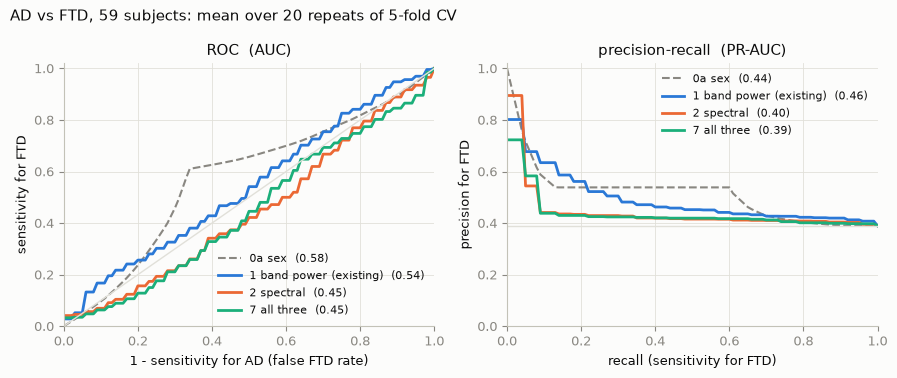

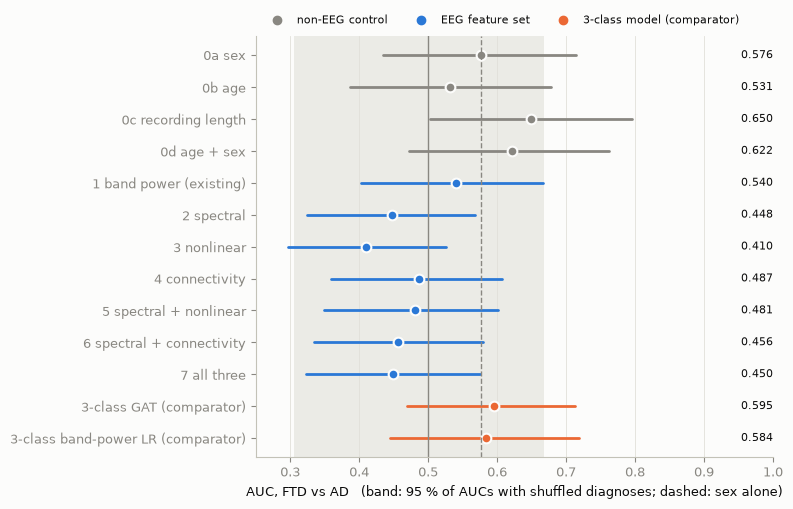

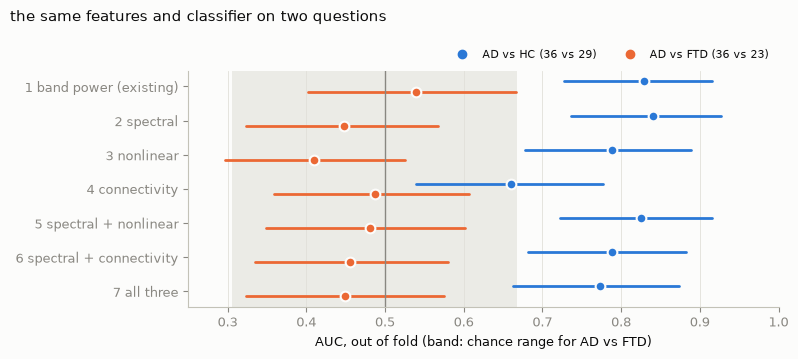

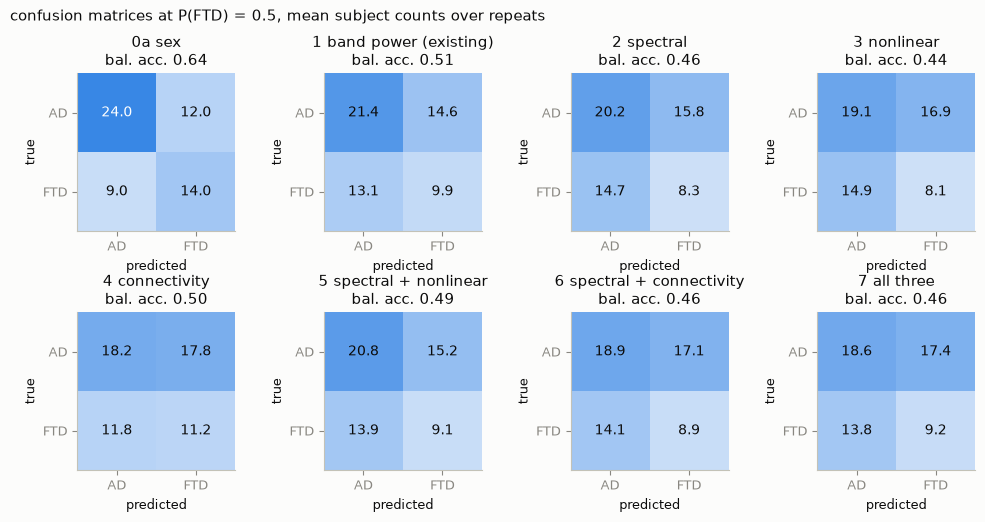

In [10]:
# ===========================================================================
# CELL 10 — FIGURES: ROC and precision-recall, AUC per experiment, confusion matrices
# ===========================================================================
def mean_curve(p, kind):
    """Curve averaged over repeats on a fixed grid (x = FPR for ROC, recall for PR)."""
    grid = np.linspace(0, 1, 101)
    ys = []
    for row in p:
        if kind == "roc":
            fpr, tpr, _ = roc_curve(y, row)
            ys.append(np.interp(grid, fpr, tpr))
        else:
            prec, rec, _ = precision_recall_curve(y, row)       # recall falls along the arrays
            best = np.maximum.accumulate(prec)                  # best precision at this recall or higher
            ys.append(np.interp(grid, rec[::-1], best[::-1]))
    return grid, np.mean(ys, 0)


CURVES = [("1 band power (existing)", SERIES[0]), ("2 spectral", SERIES[1]), ("7 all three", SERIES[2])]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, kind, metric in zip(axes, ["roc", "pr"], ["auc", "pr_auc"]):
    g, v = mean_curve(OOF["0a sex"], kind)
    ax.plot(g, v, color=MUTED, lw=1.5, ls="--", label=f"0a sex  ({REAL['0a sex'][metric]:.2f})")
    for name, color in CURVES:
        g, v = mean_curve(OOF[name], kind)
        ax.plot(g, v, color=color, label=f"{name}  ({REAL[name][metric]:.2f})")
    if kind == "roc":
        ax.plot([0, 1], [0, 1], color=GRID, lw=1)
        ax.set(xlabel="1 - sensitivity for AD (false FTD rate)", ylabel="sensitivity for FTD", title="ROC  (AUC)")
    else:
        ax.axhline(y.mean(), color=GRID, lw=1)
        ax.set(xlabel="recall (sensitivity for FTD)", ylabel="precision for FTD", title="precision-recall  (PR-AUC)")
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc="lower right" if kind == "roc" else "upper right", fontsize=8)
fig.suptitle(f"AD vs FTD, {len(y)} subjects: mean over {N_REPEATS} repeats of 5-fold CV", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(RESULT_DIR / "roc_pr.png", dpi=200)
plt.show()

# --- AUC of every experiment, with its 95 % CI ----------------------------------------
names = list(ALL)[::-1]
kind_color = lambda k: MUTED if k.startswith("0") else SERIES[1] if "comparator" in k else SERIES[0]
fig, ax = plt.subplots(figsize=(8, 0.32 * len(names) + 1))
for i, k in enumerate(names):
    lo, hi = np.percentile(BOOT[k]["auc"], [2.5, 97.5])
    ax.plot([lo, hi], [i, i], color=kind_color(k), lw=2, solid_capstyle="round")
    ax.plot(REAL[k]["auc"], i, "o", color=kind_color(k), ms=7, mec="#fcfcfb", mew=1.5)
    ax.text(1.0, i, f"{REAL[k]['auc']:.3f}", va="center", ha="right", fontsize=8, color=INK)
chance = (CHANCE.null_low.mean(), CHANCE.null_high.mean())
ax.axvspan(*chance, color=GRID, alpha=0.6, lw=0, zorder=0)
ax.axvline(0.5, color=MUTED, lw=1)
ax.axvline(REAL["0a sex"]["auc"], color=MUTED, lw=1, ls="--")
ax.set_yticks(range(len(names)), names)
ax.set(xlim=(0.25, 1.0), xlabel="AUC, FTD vs AD   (band: 95 % of AUCs with shuffled diagnoses; dashed: sex alone)")
ax.grid(axis="y", visible=False)
for c, lab in [(MUTED, "non-EEG control"), (SERIES[0], "EEG feature set"), (SERIES[1], "3-class model (comparator)")]:
    ax.plot([], [], "o", color=c, label=lab)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(RESULT_DIR / "auc_by_experiment.png", dpi=200, bbox_inches="tight")
plt.show()

# --- the same features on two questions: AD vs HC (positive control) and AD vs FTD -----
fig, ax = plt.subplots(figsize=(8, 3.6))
rows_ = CONTROL.iloc[::-1].reset_index(drop=True)
for i, r in rows_.iterrows():
    lo, hi = np.percentile(BOOT[r.experiment]["auc"], [2.5, 97.5])
    for off, (v, a, b, c) in zip([0.15, -0.15], [(r.auc_AD_vs_HC, r.ci_low, r.ci_high, SERIES[0]),
                                                  (r.auc_AD_vs_FTD, lo, hi, SERIES[1])]):
        ax.plot([a, b], [i + off, i + off], color=c, lw=2, solid_capstyle="round")
        ax.plot(v, i + off, "o", color=c, ms=7, mec="#fcfcfb", mew=1.5)
ax.axvspan(*chance, color=GRID, alpha=0.6, lw=0, zorder=0)
ax.axvline(0.5, color=MUTED, lw=1)
ax.set_yticks(range(len(rows_)), rows_.experiment)
ax.set(xlim=(0.25, 1.0), xlabel="AUC, out of fold (band: chance range for AD vs FTD)")
fig.suptitle("the same features and classifier on two questions", x=0.01, ha="left")
ax.grid(axis="y", visible=False)
ax.plot([], [], "o", color=SERIES[0], label=f"AD vs HC ({len(pos_hc)} vs {len(neg_hc)})")
ax.plot([], [], "o", color=SERIES[1], label=f"AD vs FTD ({int((y == 0).sum())} vs {int((y == 1).sum())})")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(RESULT_DIR / "two_questions.png", dpi=200, bbox_inches="tight")
plt.show()

# --- confusion matrices at the 0.5 cut, mean counts over repeats ----------------------
show = ["0a sex"] + EEG_SETS
fig, axes = plt.subplots(2, 4, figsize=(10, 5.2))
for ax, k in zip(axes.ravel(), show):
    m = np.array([[REAL[k]["tn"], REAL[k]["fp"]], [REAL[k]["fn"], REAL[k]["tp"]]])
    ax.imshow(m, cmap=SEQUENTIAL, vmin=0, vmax=max(len(_pos), len(_neg)))
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=10,
                color="#ffffff" if v > 0.6 * len(_neg) else INK)
    ax.set_xticks([0, 1], ["AD", "FTD"])
    ax.set_yticks([0, 1], ["AD", "FTD"])
    ax.set(title=f"{k}\nbal. acc. {REAL[k]['bal_acc']:.2f}", xlabel="predicted", ylabel="true")
    ax.grid(False)
fig.suptitle("confusion matrices at P(FTD) = 0.5, mean subject counts over repeats", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(RESULT_DIR / "confusion.png", dpi=200)
plt.show()

---
## Which features, and where on the scalp? (Cell 11)

- **Weights.** The inputs are standardised, so a coefficient is the change in
  the log-odds of FTD per standard deviation of the feature. For a linear model
  the mean |SHAP| value is |coefficient| × mean |z|, so this ranking *is* the
  SHAP ranking. Permutation importance on about 12 test subjects per fold would
  mostly measure noise. Sign stability is the share of the 100 fits that agree
  with the mean's sign.
- **One feature at a time** (descriptive). AUC and Mann–Whitney p on all 59
  subjects, Benjamini–Hochberg-corrected over the 210 features. Nothing here
  feeds a model.

A feature that ranks high here is a lead, **not a validated biomarker**: the
models that use these features do not beat chance (Cell 8).

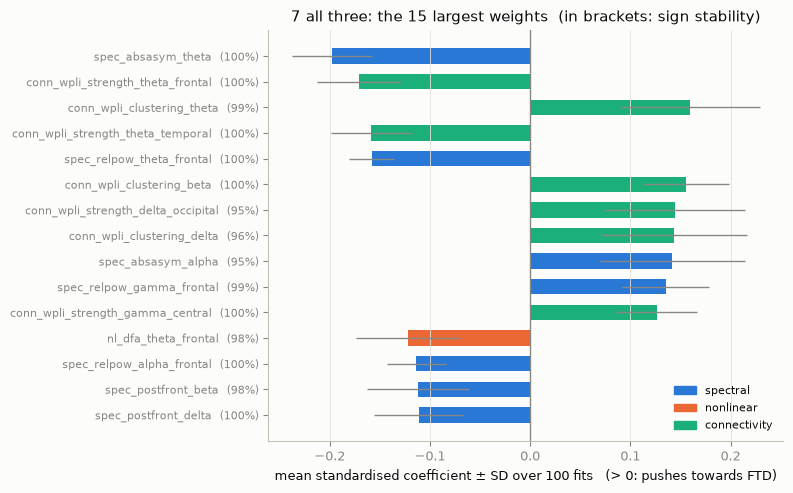

one feature at a time (210 features, Benjamini-Hochberg q over all of them)
                    feature      group   auc higher_in     p  q_fdr
                bp_theta_Fz band power 0.302        AD 0.011  1.000
                bp_theta_F3 band power 0.319        AD 0.020  1.000
                bp_theta_F4 band power 0.326        AD 0.026  1.000
                bp_theta_F7 band power 0.341        AD 0.041  1.000
                bp_gamma_T3 band power 0.656       FTD 0.046  1.000
                bp_theta_P3 band power 0.345        AD 0.048  1.000
                bp_theta_F8 band power 0.351        AD 0.057  1.000
                bp_theta_T3 band power 0.354        AD 0.061  1.000
                bp_delta_F8 band power 0.355        AD 0.063  1.000
                bp_delta_F4 band power 0.357        AD 0.068  1.000
  spec_relpow_theta_frontal   spectral 0.361        AD 0.075  1.000
spec_relpow_theta_occipital   spectral 0.364        AD 0.080  1.000
 spec_relpow_theta_temporal   spectral 0

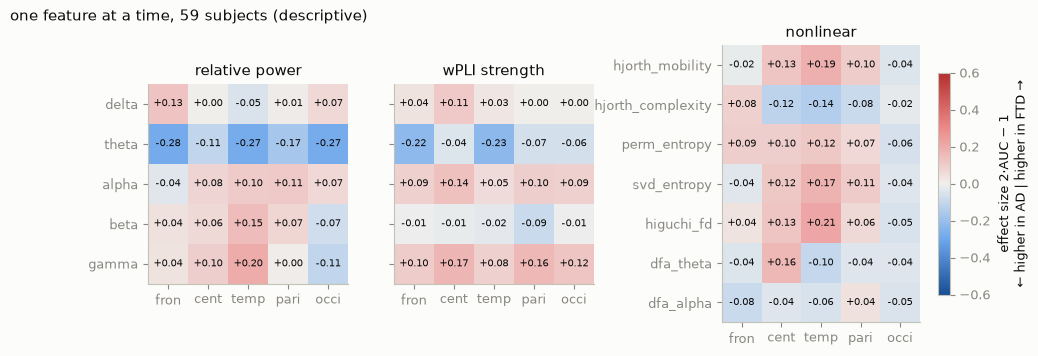

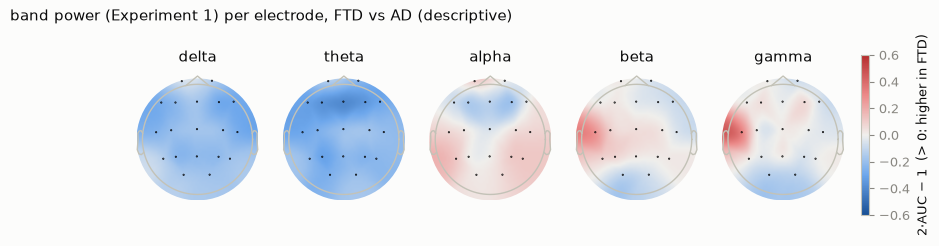

In [11]:
# ===========================================================================
# CELL 11 — WHICH FEATURES DRIVE THE MODEL?
# ===========================================================================
# (a) Model weights. Inputs are standardised, so a coefficient is the change in
#     log-odds of FTD per standard deviation. For a linear model the mean |SHAP|
#     value is |coefficient| x mean |z|, so this ranking is also the SHAP ranking.
#     Sign stability = share of the 100 fits whose coefficient has the mean's sign.
GROUP_OF = {"bp": "band power", "spec": "spectral", "nl": "nonlinear", "conn": "connectivity"}
GROUP_COLOR = {"spectral": SERIES[0], "nonlinear": SERIES[1], "connectivity": SERIES[2]}
coef_rows = []
for k, cs in SETS.items():
    w = COEF[k]
    stable = (np.sign(w) == np.sign(w.mean(0))).mean(0)
    coef_rows += [dict(experiment=k, feature=c, group=GROUP_OF[c.split("_")[0]], mean_coef=m, sd=s,
                       sign_stability=st) for c, m, s, st in zip(cs, w.mean(0), w.std(0), stable)]
COEFS = pd.DataFrame(coef_rows)

top = COEFS[COEFS.experiment == "7 all three"].reindex(
    COEFS[COEFS.experiment == "7 all three"].mean_coef.abs().sort_values(ascending=False).index).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(range(len(top)), top.mean_coef, xerr=top.sd, color=[GROUP_COLOR[g] for g in top.group],
        height=0.6, error_kw=dict(ecolor=MUTED, lw=1))
ax.set_yticks(range(len(top)), [f"{f}  ({s:.0%})" for f, s in zip(top.feature, top.sign_stability)], fontsize=8)
ax.axvline(0, color=MUTED, lw=1)
ax.set(xlabel="mean standardised coefficient ± SD over 100 fits   (> 0: pushes towards FTD)",
       title="7 all three: the 15 largest weights  (in brackets: sign stability)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLOR.items()], loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(RESULT_DIR / "coefficients.png", dpi=200)
plt.show()

# (b) One feature at a time, on all 59 subjects: DESCRIPTIVE ONLY. Nothing here feeds
#     a model; a feature that separates the groups here is not a validated biomarker.
uni = []
for c in sorted(set(sum(SETS.values(), []))):
    x = EEG[c].to_numpy()
    uni.append(dict(feature=c, group=GROUP_OF[c.split("_")[0]], auc=auc_of(x),
                    p=stats.mannwhitneyu(x[y == 1], x[y == 0]).pvalue,
                    median_AD=np.median(x[y == 0]), median_FTD=np.median(x[y == 1])))
UNI = pd.DataFrame(uni)
UNI["q_fdr"] = stats.false_discovery_control(UNI.p)            # Benjamini-Hochberg over all features
UNI["higher_in"] = np.where(UNI.auc > 0.5, "FTD", "AD")
UNI = UNI.reindex((UNI.auc - 0.5).abs().sort_values(ascending=False).index)
print(f"one feature at a time ({len(UNI)} features, Benjamini-Hochberg q over all of them)")
print(UNI.head(15)[["feature", "group", "auc", "higher_in", "p", "q_fdr"]].to_string(
    index=False, float_format=lambda v: f"{v:.3f}"))
print(f"features with q < 0.05: {int((UNI.q_fdr < 0.05).sum())} of {len(UNI)}")

# (c) Where on the scalp, and in which band: effect size 2 x AUC - 1 (rank-biserial)
REGIONS = ["frontal", "central", "temporal", "parietal", "occipital"]
BANDS = ["delta", "theta", "alpha", "beta", "gamma"]
NL = ["hjorth_mobility", "hjorth_complexity", "perm_entropy", "svd_entropy", "higuchi_fd"]
eff = lambda c: 2 * auc_of(EEG[c]) - 1
panels = [("relative power", BANDS, lambda r, b: f"spec_relpow_{b}_{r}"),
          ("wPLI strength", BANDS, lambda r, b: f"conn_wpli_strength_{b}_{r}"),
          ("nonlinear", NL + ["dfa_theta", "dfa_alpha"], lambda r, f: f"nl_{f}_{r}")]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw=dict(width_ratios=[5, 5, 7]))
for ax, (title, rows_, name) in zip(axes, panels):
    m = np.array([[eff(name(r, b)) for r in REGIONS] for b in rows_])
    im = ax.imshow(m, cmap=DIVERGING, vmin=-0.6, vmax=0.6)
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7, color=INK)
    ax.set_xticks(range(len(REGIONS)), [r[:4] for r in REGIONS])
    ax.set_yticks(range(len(rows_)), rows_ if title != "wPLI strength" else [])   # same rows as its left neighbour
    ax.set_title(title)
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02)
cb.set_label("effect size 2·AUC − 1\n← higher in AD | higher in FTD →")
fig.suptitle("one feature at a time, 59 subjects (descriptive)", x=0.01, ha="left")
fig.savefig(RESULT_DIR / "regions.png", dpi=200, bbox_inches="tight")
plt.show()

# (d) The existing band power per electrode, as scalp maps
info = mne.create_info([c.split("_")[2] for c in SETS["1 band power (existing)"][:19]], 500.0, "eeg")
info.set_montage("standard_1020")
fig, axes = plt.subplots(1, 5, figsize=(11, 2.6))
for ax, b in zip(axes, BANDS):
    v = np.array([eff(f"bp_{b}_{ch}") for ch in info.ch_names])
    im, _ = mne.viz.plot_topomap(v, info, axes=ax, cmap=DIVERGING, vlim=(-0.6, 0.6), show=False, contours=0)
    ax.set_title(b)
cb = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02)
cb.set_label("2·AUC − 1  (> 0: higher in FTD)")
fig.suptitle("band power (Experiment 1) per electrode, FTD vs AD (descriptive)", x=0.01, ha="left")
fig.savefig(RESULT_DIR / "topomaps.png", dpi=200, bbox_inches="tight")
plt.show()

---
## Sex (Cell 12)

Sex is the one non-EEG quantity both unbalanced between the groups (FTD 61 %
male, AD 33 %) and able to reach the EEG, since amplitude depends partly on
skull thickness. Cell 12 scores the same predictions within each sex. It then
runs a **supplementary** experiment, the only place a demographic variable
enters a model: sex alone against sex plus each EEG set. That measures what the
EEG adds.

In [12]:
# ===========================================================================
# CELL 12 — IS THE EEG ONLY DETECTING SEX?
# ===========================================================================
# FTD has more men than AD here (Cell 3), and EEG amplitude differs between the
# sexes. Two checks: (a) the same predictions, scored within women and within men
# separately; (b) SUPPLEMENTARY models that are given sex explicitly, compared with
# sex alone. Only (b) uses a demographic input, and only to measure what EEG adds.
male = CTRL.male.to_numpy().astype(bool)
print(f"(a) AUC within one sex   women: {int((~male & (y == 0)).sum())} AD / {int((~male & (y == 1)).sum())} FTD"
      f"   men: {int((male & (y == 0)).sum())} AD / {int((male & (y == 1)).sum())} FTD")
within = []
for k in EEG_SETS:
    w = np.mean([roc_auc_score(y[~male], p[~male]) for p in OOF[k]])
    m = np.mean([roc_auc_score(y[male], p[male]) for p in OOF[k]])
    within.append(dict(experiment=k, auc_all=REAL[k]["auc"], auc_women=w, auc_men=m))
WITHIN = pd.DataFrame(within)
print(WITHIN.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

SUPP = {}
for k, cs in SETS.items():
    name = f"S sex + {k}"
    SUPP[name], _ = cross_validate(pd.concat([CTRL[["male"]], EEG[cs]], axis=1))
    REAL[name], BOOT[name] = metrics(SUPP[name]), metrics(SUPP[name], _bpos, _bneg)
SUPP_CMP = compare([(k, "0a sex") for k in SUPP], "supplementary: does EEG add to sex?")
COMPARISONS = pd.concat([COMPARISONS, SUPP_CMP], ignore_index=True)
print(f"\n(b) supplementary: sex + EEG vs sex alone   (Holm over {len(SUPP_CMP)})")
print(f"{'A vs B':48s}{'AUC A':>8s}{'dAUC':>8s}{'95% CI':>18s}{'p':>7s}{'p Holm':>8s}")
print("-" * 97)
for r in SUPP_CMP.itertuples():
    print(f"{r.a + ' vs ' + r.b:48s}{REAL[r.a]['auc']:8.3f}{r.d_auc:+8.3f}{r.ci95_auc:>18s}{r.p:7.3f}"
          f"{r.p_holm:7.3f}{'*' if r.p_holm < 0.05 else ' '}")

(a) AUC within one sex   women: 24 AD / 9 FTD   men: 12 AD / 14 FTD


               experiment  auc_all  auc_women  auc_men
  1 band power (existing)    0.540      0.725    0.327
               2 spectral    0.448      0.534    0.324
              3 nonlinear    0.410      0.359    0.443
           4 connectivity    0.487      0.559    0.374
   5 spectral + nonlinear    0.481      0.519    0.430
6 spectral + connectivity    0.456      0.550    0.334
              7 all three    0.450      0.510    0.354



(b) supplementary: sex + EEG vs sex alone   (Holm over 7)
A vs B                                             AUC A    dAUC            95% CI      p  p Holm
-------------------------------------------------------------------------------------------------
S sex + 1 band power (existing) vs 0a sex          0.560  -0.016  [-0.189, +0.151]  0.836  1.000 
S sex + 2 spectral vs 0a sex                       0.484  -0.092  [-0.230, +0.039]  0.170  1.000 
S sex + 3 nonlinear vs 0a sex                      0.482  -0.094  [-0.208, +0.011]  0.067  0.469 
S sex + 4 connectivity vs 0a sex                   0.522  -0.054  [-0.198, +0.082]  0.433  1.000 
S sex + 5 spectral + nonlinear vs 0a sex           0.504  -0.072  [-0.229, +0.069]  0.336  1.000 
S sex + 6 spectral + connectivity vs 0a sex        0.475  -0.101  [-0.259, +0.050]  0.187  1.000 
S sex + 7 all three vs 0a sex                      0.470  -0.106  [-0.267, +0.044]  0.181  1.000 


In [13]:
# ===========================================================================
# CELL 13 — SAVE results/
# ===========================================================================
np.savez_compressed(RESULT_DIR / "oof_prob.npz", participant_id=IDS, y_ftd=y,
                    **{k.replace(" ", "_"): v for k, v in {**ALL, **SUPP}.items()})
NFEAT = {**{k: len(v) for k, v in {**CONTROL_SETS, **SETS}.items()},
         **{f"S sex + {k}": len(v) + 1 for k, v in SETS.items()}}
summary = pd.DataFrame([dict(experiment=k, n_features=NFEAT.get(k),
                             **{m: REAL[k][m] for m in REAL[k]},
                             **{f"{m}_ci_low": np.percentile(BOOT[k][m], 2.5) for m in ["auc", "pr_auc", "bal_acc"]},
                             **{f"{m}_ci_high": np.percentile(BOOT[k][m], 97.5) for m in ["auc", "pr_auc", "bal_acc"]})
                        for k in REAL])
summary.to_csv(RESULT_DIR / "summary.csv", index=False, float_format="%.4f")
COMPARISONS.to_csv(RESULT_DIR / "comparisons.csv", index=False, float_format="%.4f")
CHANCE.to_csv(RESULT_DIR / "above_chance.csv", index=False, float_format="%.4f")
CONTROL.to_csv(RESULT_DIR / "positive_control_ad_vs_hc.csv", index=False, float_format="%.4f")
COEFS.to_csv(RESULT_DIR / "coefficients.csv", index=False, float_format="%.4f")
UNI.to_csv(RESULT_DIR / "univariate.csv", index=False, float_format="%.4g")
CONFOUND.to_csv(RESULT_DIR / "confounders.csv", index=False, float_format="%.4f")
WITHIN.to_csv(RESULT_DIR / "within_sex.csv", index=False, float_format="%.4f")
(RESULT_DIR / "protocol.json").write_text(json.dumps(dict(
    subjects=dict(AD=int((y == 0).sum()), FTD=int((y == 1).sum())), positive_class=POSITIVE,
    data="first 75 join-free 4 s epochs per subject (features_ad_ftd.ipynb)",
    cv=dict(n_folds=N_FOLDS, n_repeats=N_REPEATS, seeds=f"{SEED} + 1000 x repeat", unit="subject"),
    model=f"StandardScaler + LogisticRegression(L2, C={C_LR}, class_weight='balanced'), fitted per fold",
    feature_sets={k: v for k, v in {**CONTROL_SETS, **SETS}.items()},
    statistics=dict(n_boot=N_BOOT, ci="percentile, subjects resampled within class",
                    p="two-sided bootstrap, same resamples", correction="Holm within each family",
                    above_chance=f"{N_PERM} label shuffles x {PERM_REPEATS} repeats, one-sided")), indent=1))
for p in sorted(RESULT_DIR.iterdir()):
    print(f"  {p.name:30s} {p.stat().st_size / 1024:7.0f} KB")

  above_chance.csv                     0 KB
  auc_by_experiment.png              119 KB
  coefficients.csv                    36 KB
  coefficients.png                   134 KB
  comparisons.csv                      3 KB
  confounders.csv                      0 KB
  confusion.png                      157 KB
  oof_prob.npz                       155 KB
  positive_control_ad_vs_hc.csv        0 KB
  protocol.json                       15 KB
  regions.png                        162 KB
  roc_pr.png                         166 KB
  summary.csv                          3 KB
  topomaps.png                       175 KB
  two_questions.png                   73 KB
  univariate.csv                      13 KB
  within_sex.csv                       0 KB


---
## Reading the result

**The answer to the question is no.** No feature group separates AD from FTD
above chance, on this dataset, at this sample size:

| | AUC, FTD vs AD [95 % CI] |
|---|---|
| existing band power (1) | 0.540 [0.403, 0.667] |
| spectral (2), nonlinear (3), connectivity (4) | 0.448, 0.410, 0.487 |
| their combinations (5–7) | 0.481, 0.456, 0.450 |
| sex alone / recording length alone (not EEG) | 0.576 / 0.650 |
| existing 3-class GAT, for comparison | 0.595 [0.469, 0.713] |
| chance, from shuffled diagnoses | about 0.49, 95 % range ≈ 0.30–0.68 |

- **No engineered group beats band power** (all six differences are negative;
  none survives Holm). **No EEG set beats knowing the patient's sex.** None is
  above chance (permutation p ≥ 0.3). AUCs below 0.5 mean no signal, not inverted
  signal: Cell 8 shows chance itself sits slightly below 0.5 in this design.
- **The features are not broken.** On AD vs healthy controls, the same sets and
  classifier reach AUC 0.83 (band power) and 0.84 (spectral). What is missing is
  the AD-vs-FTD contrast, not dementia information.
- **The non-EEG facts are at least as strong as the EEG.** Recording length
  alone reaches 0.65. Every EEG feature here uses the same 300 s per subject, so
  length cannot leak into them, but any study that windows whole recordings
  carries this signal unless it checks.
- **What differs, descriptively.** Frontal and temporal theta power is higher in
  AD (single-feature AUC ≈ 0.30, unadjusted p ≈ 0.01). That fits the stronger
  EEG slowing usually reported in AD, but none of the 210 features survives FDR
  correction.
- **The models behave differently in women and men** (band power: AUC 0.73
  within women, 0.33 within men). With 9 FTD women and 12 AD men, that is a
  warning against reading any single number here as stable.

**What this does and does not show.** It shows that with 59 subjects, equal
data per subject and an honest protocol, these resting-state features do not
separate AD from FTD. It does not show that EEG cannot. The limits:
- 23 FTD subjects;
- one site;
- no FTD subtypes in the dataset;
- 5 minutes per subject;
- one pre-specified linear classifier. A tuned or nonlinear classifier would
  be a separate test, held to the same chance level; it has not been run.

Published accuracies near 90 % for AD vs FTD on this dataset (e.g. Lal et al.
2024) used window-level splits. Under such splits, `leak_check.py` shows a
lookup with no learning at all reaching 99 %.